In [1]:
import numpy as np
import cv2
import time
from IPython.display import display, Image

def integral_image(img):
    """Trả về S kích thước (H+1, W+1), dtype int64, hàng 0 và cột 0 bằng 0."""
    H, W = img.shape
    S = np.zeros((H + 1, W + 1), dtype=np.int64)
    S[1:, 1:] = np.cumsum(np.cumsum(img.astype(np.int64), axis=0), axis=1)
    return S

def box_sum(S, y1, x1, y2, x2):
    """Tổng vùng [y1..y2, x1..x2] (bao gồm biên), vectơ hóa được."""
    return S[y2 + 1, x2 + 1] - S[y1, x2 + 1] - S[y2 + 1, x1] + S[y1, x1]

def local_mean_std(img, radius):
    """Trả về (mean, std), mỗi cái (H, W) float64. Dùng 2 ảnh tích phân."""
    H, W = img.shape
    w = 2 * radius + 1
    w2 = w * w
    
    padded = np.pad(img, radius, mode='edge').astype(np.float64)
    S1 = integral_image(padded)
    S2 = integral_image(padded ** 2)
    
    sum1 = S1[w:, w:] - S1[:-w, w:] - S1[w:, :-w] + S1[:-w, :-w]
    sum2 = S2[w:, w:] - S2[:-w, w:] - S2[w:, :-w] + S2[:-w, :-w]
    
    mean = sum1 / w2
    var = (sum2 / w2) - (mean ** 2)
    var = np.maximum(var, 0.0)
    std = np.sqrt(var)
    
    return mean, std

def adaptive_threshold(img, radius=15, method='bradley', t=0.15, k=0.34):
    """Trả về ảnh nhị phân (H, W) uint8 với giá trị 0 / 255."""
    mean, std = local_mean_std(img, radius)
    
    if method.lower() == 'bradley':
        T = mean * (1.0 - t)
    elif method.lower() == 'sauvola':
        R = 128.0
        T = mean * (1.0 + k * ((std / R) - 1.0))
    else:
        raise ValueError("Phương pháp không hợp lệ!")
        
    binary = np.where(img.astype(np.float64) < T, 255, 0).astype(np.uint8)
    return binary

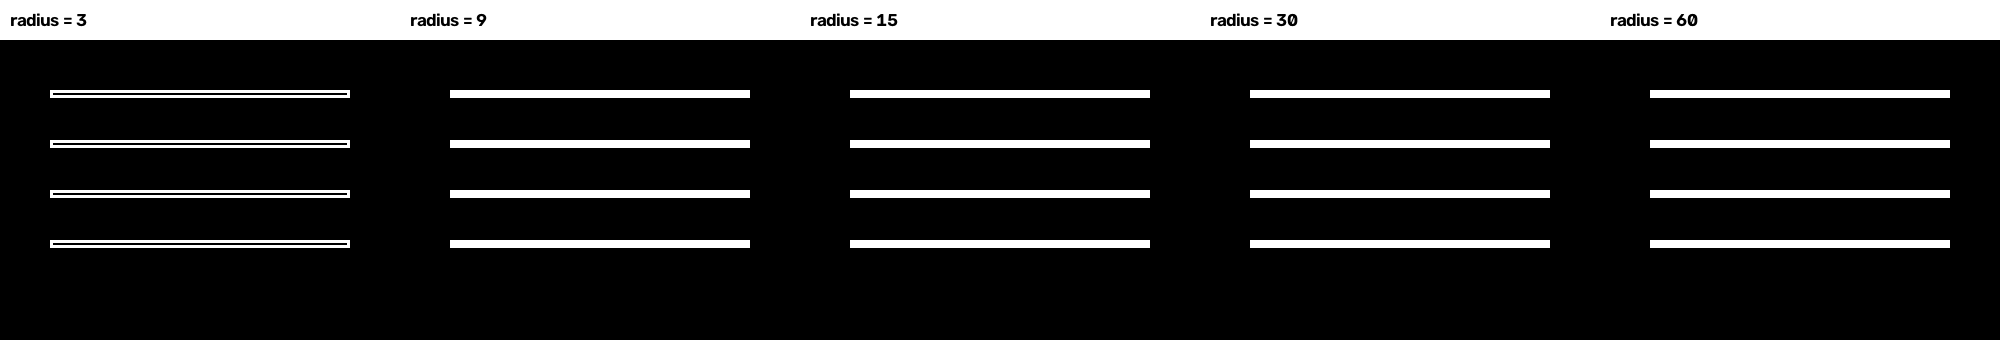

In [2]:
H, W = 300, 400
test_img = np.ones((H, W), dtype=np.uint8) * 240
lighting = np.linspace(240, 80, W)
test_img = np.clip(test_img.astype(float) - (240 - lighting), 0, 255).astype(np.uint8)
for i in range(50, 250, 50):
    test_img[i:i+8, 50:350] = 30

radii = [3, 9, 15, 30, 60]
cell_images = []
for r in radii:
    res = adaptive_threshold(test_img, radius=r, method='bradley', t=0.15)
    bgr = cv2.cvtColor(res, cv2.COLOR_GRAY2BGR)
    canvas = np.ones((H + 40, W, 3), dtype=np.uint8) * 255
    canvas[40:, :] = bgr
    cv2.putText(canvas, f"radius = {r}", (10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2, cv2.LINE_AA)
    cell_images.append(canvas)

final_radius_img = np.hstack(cell_images)
cv2.imwrite("radius_effect.png", final_radius_img)
display(Image("radius_effect.png"))

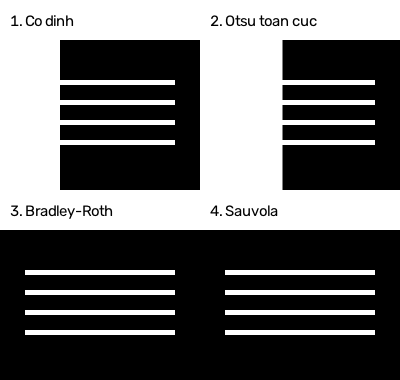

In [3]:
demo_bg = np.tile(np.linspace(50, 220, W), (H, 1)).astype(np.uint8)
demo_text = demo_bg.copy()
for i in range(80, 220, 40):
    demo_text[i:i+10, 50:350] = 10

_, thresh_fixed = cv2.threshold(demo_text, 100, 255, cv2.THRESH_BINARY_INV)
_, thresh_otsu = cv2.threshold(demo_text, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
thresh_bradley = adaptive_threshold(demo_text, radius=15, method='bradley', t=0.15)
thresh_sauvola = adaptive_threshold(demo_text, radius=15, method='sauvola', k=0.34)

def make_comp_cell(img_gray, title_text):
    cell = cv2.resize(img_gray, (200, 150))
    bgr = cv2.cvtColor(cell, cv2.COLOR_GRAY2BGR)
    canvas = np.ones((190, 200, 3), dtype=np.uint8) * 255
    canvas[40:, 0:200] = bgr
    cv2.putText(canvas, title_text, (10, 26), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
    return canvas

c1 = make_comp_cell(thresh_fixed, "1. Co dinh")
c2 = make_comp_cell(thresh_otsu, "2. Otsu toan cuc")
c3 = make_comp_cell(thresh_bradley, "3. Bradley-Roth")
c4 = make_comp_cell(thresh_sauvola, "4. Sauvola")

row1 = np.hstack([c1, c2])
row2 = np.hstack([c3, c4])
comp_grid = np.vstack([row1, row2])
cv2.imwrite("comparison_thresholds.png", comp_grid)
display(Image("comparison_thresholds.png"))

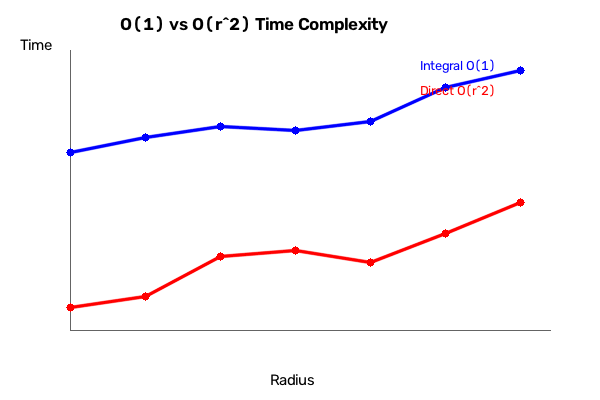

In [4]:
radii_list = [1, 2, 4, 8, 16, 32, 64]
time_integral, time_direct = [], []
dummy_img = np.random.randint(0, 256, (500, 500), dtype=np.uint8)

for r in radii_list:
    start = time.time()
    _ = local_mean_std(dummy_img, radius=r)
    time_integral.append(time.time() - start)
    
    w = 2 * r + 1
    kernel = np.ones((w, w), dtype=np.float32) / (w * w)
    start = time.time()
    _ = cv2.filter2D(dummy_img.astype(float), -1, kernel)
    time_direct.append(time.time() - start)

chart_img = np.ones((400, 600, 3), dtype=np.uint8) * 255
cv2.putText(chart_img, "O(1) vs O(r^2) Time Complexity", (120, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2, cv2.LINE_AA)
cv2.putText(chart_img, "Radius", (270, 385), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)
cv2.putText(chart_img, "Time", (20, 50), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 0, 0), 1, cv2.LINE_AA)

cv2.line(chart_img, (70, 330), (550, 330), (100, 100, 100), 1)
cv2.line(chart_img, (70, 50), (70, 330), (100, 100, 100), 1)

max_t = max(max(time_integral), max(time_direct)) if max(max(time_integral), max(time_direct)) > 0 else 1

pts_int, pts_dir = [], []
for i, r in enumerate(radii_list):
    px = int(70 + (i / (len(radii_list) - 1)) * 450)
    py_i = int(330 - (time_integral[i] / max_t) * 260)
    py_d = int(330 - (time_direct[i] / max_t) * 260)
    pts_int.append((px, py_i))
    pts_dir.append((px, py_d))
    
    cv2.circle(chart_img, (px, py_i), 4, (255, 0, 0), -1)
    cv2.circle(chart_img, (px, py_d), 4, (0, 0, 255), -1)

for i in range(len(pts_int) - 1):
    cv2.line(chart_img, pts_int[i], pts_int[i+1], (255, 0, 0), 2, cv2.LINE_AA)
    cv2.line(chart_img, pts_dir[i], pts_dir[i+1], (0, 0, 255), 2, cv2.LINE_AA)

cv2.putText(chart_img, "Integral O(1)", (420, 70), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 0, 0), 1, cv2.LINE_AA)
cv2.putText(chart_img, "Direct O(r^2)", (420, 95), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 255), 1, cv2.LINE_AA)

cv2.imwrite("time_complexity.png", chart_img)
display(Image("time_complexity.png"))